<a href="https://colab.research.google.com/github/CorreaMartinezLuisAngel/Metodos-Numericos-I/blob/main/M%C3%A9todo_de_Newton_Raphson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<font color="Brown"><h1><b>
Método de Newton Raphson
</h1></b></font>

<font face="Georgia" size="3" color="brown">
Objetivo:
</font>
<font face="Georgia" size="3">
Partimos de querer resolver el problema $f(x)=0$
</font>

<font face="Georgia" size="3" color="brown">
¿De dónde viene el método de Newton?:
</font>
<font size="3" face="Georgia">
Suponga que $f \in C^2[a, b]$ y si $p_0 \in [a, b]$ es una aproximación para $p$, de tal forma que $f'(p_0) \neq 0$ y $|p - p_0|$ es "pequeño". Considere que el primer polinomio de Taylor para $f(x)$ expandido alrededor de $p_0$ y evaluado en $x = p$:<br><br>
<center>
$f(p) = f(p_0) + (p - p_0)f'(p_0) + \frac{(p - p_0)^2}{2} f''(\xi(p))$
</center><br>
donde $\xi(p)$ se encuentra entre $p$ y $p_0$ y pesto que $f(p) = 0$, esta ecuación nos da<br><br>
<center>
$0 = f(p_0) + (p - p_0)f'(p_0) + \frac{(p - p_0)^2}{2} f''(\xi(p))$
</center><br>

<font size="3" face="Georgia">
El método de Newton se deriva al suponer que como $|p - p_0|$ es pequeño, el término relacionado con $(p - p_0)^2$ es mucho más pequeño, entonces<br><br>
<center>
$0 \approx f(p_0) + (p - p_0)f'(p_0)$
</center><br>
Al resolver para $p$ obtenemos<br><br>
<center>
$p \approx p_0 - \frac{f(p_0)}{f'(p_0)} \equiv p_1$
</center><br>
Esto constituye la base para el método de Newton, que empieza con una aproximación inicial $p_0$ y genera la sucesión $\{p_n\}_{n=0}^{\infty}$, mediante<br><br>
<center>
$p_n = p_{n-1} - \frac{f(p_{n-1})}{f'(p_{n-1})}, \quad \text{para } n \ge 1.$
</center><br>
Este proceso se repite hasta que se tenga la tolerancia deseada en nuestra aproximación.<br><br>
</font>

<font size="3" face="Georgia">
El siguiente código es la representación de este método, usando como ejemplo el ejercicio 1 de la página 51 del libro de Burden:
</font>

In [9]:
#Importamos las librerías necesarias
import numpy as np

<font face="Georgia" size="3">
Primero veamos que $f \in C^2 [0, \frac {\pi}{2}]$<br><br>
$f(x)=\cos(x) - x$ , en $[0, \frac {\pi}{2}]$<br>
$f(0)=\cos(0)-0=1$<br>
$f(\frac {\pi}{2})=\cos(\frac{\pi}{2})-\frac{\pi}{2}=-\frac{\pi}{2}$<br><br>
$f'(x)=-\sin(x)-1$<br>
$f'(0)=-\sin(0)-1=-1$<br>
$f'(\frac {\pi}{2})=-\sin(\frac {\pi}{2})-1=-2$<br><br>
$f''(x)=-\cos(x)$<br>
$f''(0)=-\cos(0)=-1$<br>
$f''(\frac {\pi}{2})=-\cos(\frac{\pi}{2})=0$<br><br>
Por tanto $f \in C^2 [0,\frac {\pi}{2}]$
</font>

In [10]:
#Datos
p0=np.pi/4 #Punto inicial Iteracion
tol=0.001 #Precision
N0=100 #Numero máximo de iteraciones
i=1 #Contador
error=1

#Intervalo
a=0
b=np.pi/2

#Definimos una función
def f(x):
    return np.cos(x)-x

#Definimos la derivada de nuestra función
def df(x):
    return (-1)*np.sin(x)-1

<font face="Georgia" size="3">
Ahora necesitamos comprobar que $f'(p_0)≠0$, entonces tomemos $p_0=\frac{\pi}{4}$ y veamos si es continua:
</font>

In [11]:
#Comprobamos la derivada en p0 no sea 0
fp0=f(p0)
dfp0=df(p0)
print(f"La función evaluada en {p0} es {fp0}")
print(f"La derivada evaluada en {p0} es {dfp0}")
if dfp0==0:
  print(f"la derivada en este punto es 0 por lo cual el método no puede continuar")

La función evaluada en 0.7853981633974483 es -0.0782913822109007
La derivada evaluada en 0.7853981633974483 es -1.7071067811865475


<font face="Georgia" size="3">
Así entonces nuestra función de Iteracion es:<br>
$p_n=p_{n-1}-\frac{\cos(p_{n-1})}{-\sin(p_{n-1})-1}$<br>
Y $p_0=\frac{\pi}{4}$
</font>

In [12]:
#Encabezado de la tabla
print("iter\tpn-1\t\tp\t\terror")

#Ciclo iterativo
while i<=N0 and error>=tol:
    fp0=f(p0)
    dfp0=df(p0)
    if dfp0==0:
        print(f"Error la derivada en la Iteración {i} es 0, no se puede continuar con el proceso")
        break

    p=p0-(fp0/dfp0)
    error=abs(p-p0)
    print("{0}\t{1:.6f}\t{2:.6f}\t{3:.6f}".format(i, p0, p, error))

    i+=1
    p0=p

#Resultado
print("-" * 112) #Linea de separación
if i>=N0:
        print(f"El método fracasó después de {i} iteraciones.")
else:
        print(f"La raíz de la función dada es {p:.6f}")

iter	pn-1		p		error
1	0.785398	0.739536	0.045862
2	0.739536	0.739085	0.000451
----------------------------------------------------------------------------------------------------------------
La raíz de la función dada es 0.739085


<font face="Georgia" size="3">
Ahora veamos la aproximación que obtuvimos en una gráfica:
</font>

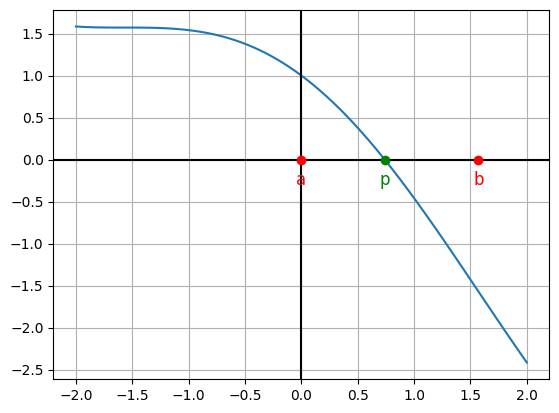

In [17]:
#Veamos una gráfica de la función que iteramos
import numpy as np
import matplotlib.pyplot as plt

#Impresión de la funcion
xx=np.linspace(-2,2,100)
plt.plot(xx,f(xx))

#Impresión de los ejes
plt.axhline(0, color='black')  # Eje X
plt.axvline(0, color='black')  # Eje Y

#Impresion de los puntos
plt.plot(a,0,'ro') #Punto incial a
plt.plot(b,0,'ro') #Punto incial b
plt.plot(p,0,'go') #Aproximacion obtenida

#Rotulos
plt.text(a, -0.3, 'a', color='red', fontsize=12, ha='center')
plt.text(b, -0.3, 'b', color='red', fontsize=12, ha='center')
plt.text(p, -0.3, 'p', color='green', fontsize=12, ha='center')

#Cuadricula
plt.grid()

<font face="Georgia" size="3" color="brown">
Conclusión:
</font>
<font face="Georgia" size="3">
El método de Newton-Raphson es un método bastante rápido para hallar raíces en comparación con otros métodos como el de bisección, siempre y cuando se cumplan las condiciones necesarias y, de manera esencial, que $f'(p)≠0$, ya que si la derivada es cero (o muy cercana a cero) en la raíz, el método puede fallar o no converger a la solución.
</font>